In [1]:
print("Roll No: 24BAD015")
print("Name: BALA HARSHINI B")
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
max_words = 10000
max_len = 200
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=max_words)

word_index = imdb.get_word_index()
reverse_word_index = {v + 3: k for k, v in word_index.items()}
reverse_word_index[0] = ""
reverse_word_index[1] = ""
reverse_word_index[2] = ""

def decode_review(sequence):
    return " ".join(reverse_word_index.get(i, "?") for i in sequence)
print("\nSample Review:")
print(decode_review(x_train[0])[:500])
print("Sentiment:", "Positive" if y_train[0] == 1 else "Negative")

x_train = pad_sequences(x_train, maxlen=max_len, padding="post", truncating="post")
x_test = pad_sequences(x_test, maxlen=max_len, padding="post", truncating="post")

x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=0.2, random_state=42
)

print("\nTraining samples:", len(x_train))
print("Validation samples:", len(x_val))
print("Testing samples:", len(x_test))
print("Input shape:", x_train.shape)

Roll No: 24BAD015
Name: BALA HARSHINI B
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Sample Review:
 this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert  is an amazing actor and now the same being director  father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for  and would recommend it to everyone
Sentiment: Positive

Training samples: 20000
Validation samples: 5000
Testing samples: 25000
Input shape: (20000, 200)


In [5]:
print("24BAD015- BALA HARSHINI B")
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
model = Sequential([
    Embedding(max_words, 64, input_length=max_len),
    LSTM(64),
    Dense(1, activation="sigmoid")
])
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
model.build(input_shape=(None, max_len))
model.summary()

24BAD015- BALA HARSHINI B


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

24BAD015- BALA HARSHINI B
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 59s 363ms/step - accuracy: 0.6259 - loss: 0.6275 - val_accuracy: 0.6608 - val_loss: 0.6438
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 58s 368ms/step - accuracy: 0.7045 - loss: 0.5978 - val_accuracy: 0.6926 - val_loss: 0.5917
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 82s 367ms/step - accuracy: 0.6737 - loss: 0.6246 - val_accuracy: 0.6716 - val_loss: 0.6249
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 57s 363ms/step - accuracy: 0.7507 - loss: 0.5332 - val_accuracy: 0.8104 - val_loss: 0.4849
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 58s 371ms/step - accuracy: 0.5779 - loss: 0.6783 - val_accuracy: 0.5252 - val_loss: 0.6871
Training Accuracy: 0.5779
Validation Accuracy: 0.5252
Training Loss: 0.6783
Validation Loss: 0.6871
Test Loss: 0.6876
Test Accuracy: 0.5308

Classification Report:
              precision    recall  f1-score   support

    Negative       0.52      0.82      0.64     12500
    Positive       0.57      0.24      0.34     125

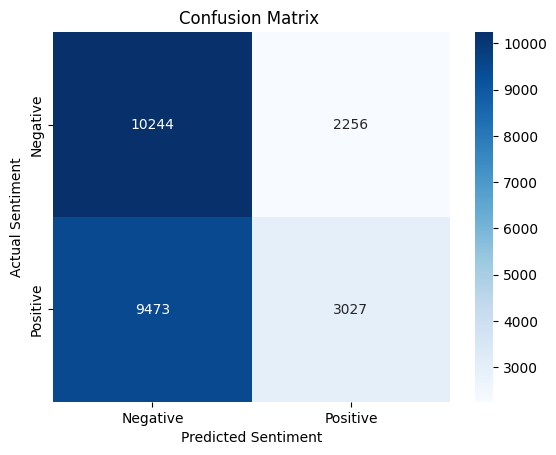

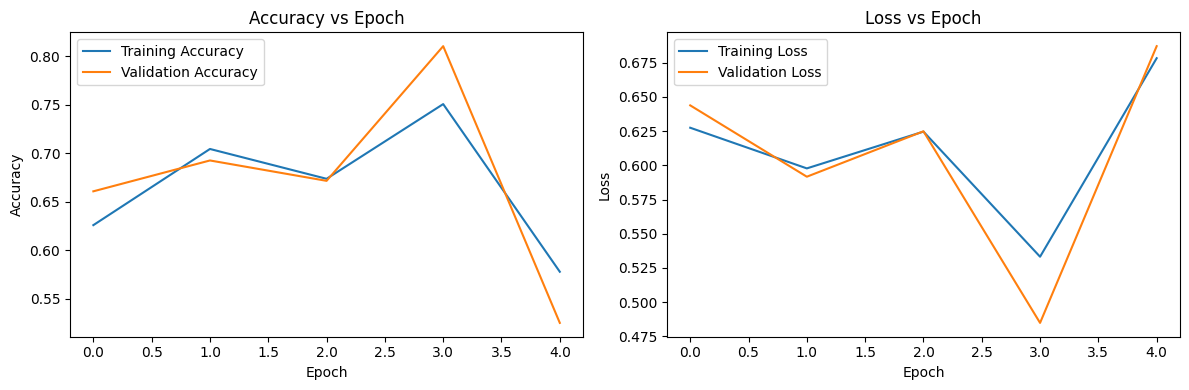

In [6]:

print("24BAD015- BALA HARSHINI B")
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_data=(x_val, y_val)
)
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print("Training Accuracy:", round(history.history["accuracy"][-1], 4))
print("Validation Accuracy:", round(history.history["val_accuracy"][-1], 4))
print("Training Loss:", round(history.history["loss"][-1], 4))
print("Validation Loss:", round(history.history["val_loss"][-1], 4))
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))
y_prob = model.predict(x_test, verbose=0)
y_pred = (y_prob >= 0.5).astype(int).flatten()

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Confusion Matrix ")
plt.show()
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Epoch")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss vs Epoch")
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
print("24BAD015- BALA HARSHINI B")
def predict_sentiment(review):
    words = review.lower().split()
    sequence = [1]

    for word in words:
        index = word_index.get(word, 2)
        if index >= max_words:
            index = 2
        sequence.append(index + 3 if index != 2 else 2)

    padded = pad_sequences(
        [sequence], maxlen=max_len,
        padding="post", truncating="post"
    )

    probability = model.predict(padded, verbose=0)[0][0]
    sentiment = "Positive" if probability >= 0.5 else "Negative"

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("Positive Probability:", round(float(probability), 4))
    return sentiment

reviews = [
    ("This movie was wonderful and the acting was excellent", "Positive"),
    ("The film was boring and a complete waste of time", "Negative"),
    ("I really enjoyed the story and the amazing performances", "Positive"),
    ("The movie was terrible and I hated every minute", "Negative"),
    ("The film was good and entertaining", "Positive"),
    ("The story was dull and the acting was poor", "Negative")
]

for review, expected in reviews:
    predicted = predict_sentiment(review)
    print("Expected Sentiment:", expected)
    print("Correct Prediction:", predicted == expected)
    print("-" * 40)

24BAD015- BALA HARSHINI B
Review: This movie was wonderful and the acting was excellent
Predicted Sentiment: Negative
Positive Probability: 0.2277
Expected Sentiment: Positive
Correct Prediction: False
----------------------------------------
Review: The film was boring and a complete waste of time
Predicted Sentiment: Negative
Positive Probability: 0.2277
Expected Sentiment: Negative
Correct Prediction: True
----------------------------------------
Review: I really enjoyed the story and the amazing performances
Predicted Sentiment: Positive
Positive Probability: 0.8574
Expected Sentiment: Positive
Correct Prediction: True
----------------------------------------
Review: The movie was terrible and I hated every minute
Predicted Sentiment: Negative
Positive Probability: 0.2277
Expected Sentiment: Negative
Correct Prediction: True
----------------------------------------
Review: The film was good and entertaining
Predicted Sentiment: Negative
Positive Probability: 0.2277
Expected Sentime